<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HancockRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Merged data shape: (763, 49)
Duplicate patient rows before filtering: 0

Target source: hpv_association_p16
Predictors: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
Target distribution:
HPV_Label
0    191
1    141
Name: count, dtype: int64

Rows: 332 | 3-fold cross-validation | No independent test set

================== FOLD 1/3 ==================
Train: 221 | Validation: 111
Class counts (train): {0: 127, 1: 94}
Class counts (validation): {0: 64, 1: 47}
Automatic class weights: {0: 0.8700787401574803, 1: 1.175531914893617}
Selected threshold: 0.445
Fold validation metrics:
Accuracy             0.657658
Balanced_Accuracy    0.652261
Precision            0.591837
Recall               0.617021
F1                   0.604167
Threshold            0.445000
ROC_AUC              0.690160
PR_AUC      

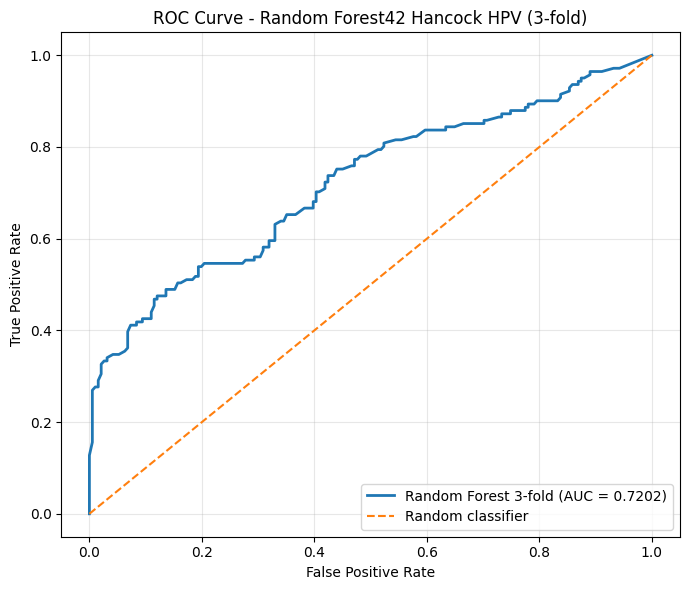

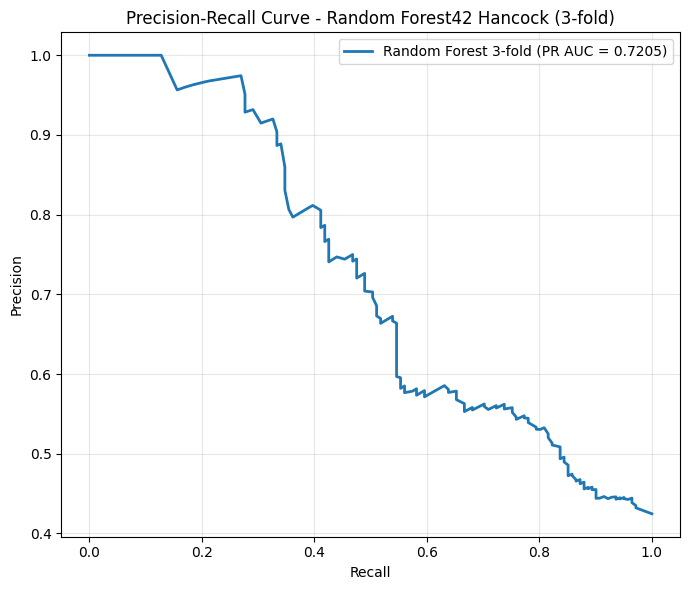


Mean Random Forest feature importance:
                 feature  mean_importance
age_at_initial_diagnosis         0.432530
                pN_stage         0.361164
          smoking_status         0.129716
                     sex         0.052434
    primarily_metastasis         0.020341
      primary_tumor_site         0.003814


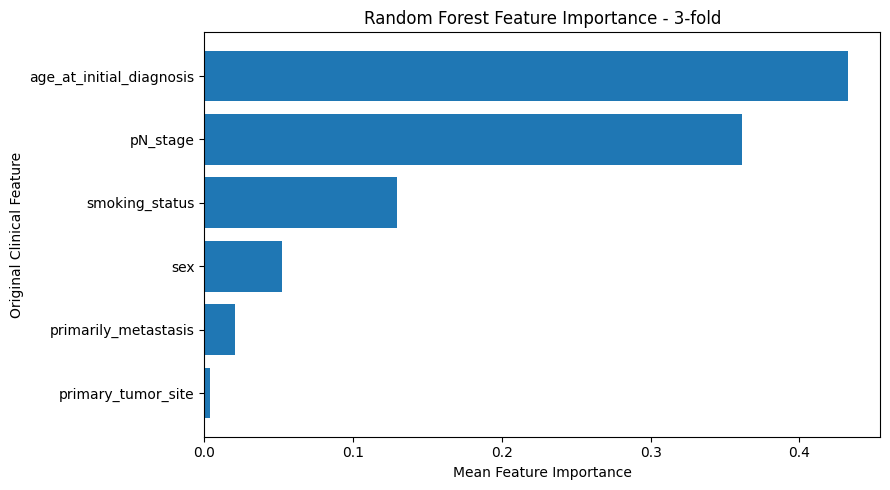


Mean absolute SHAP importance across folds:
                 feature  mean_absolute_shap
                pN_stage            0.190742
          smoking_status            0.123033
age_at_initial_diagnosis            0.084584
                     sex            0.030858
    primarily_metastasis            0.012528
      primary_tumor_site            0.001457


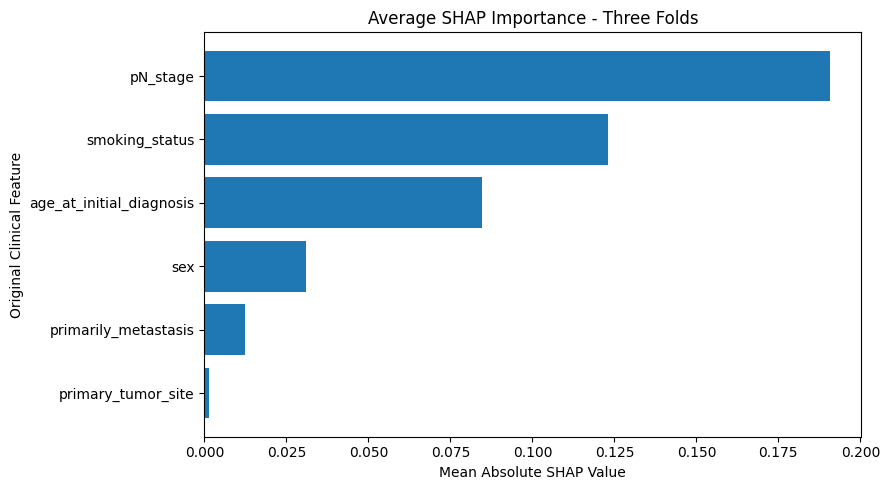

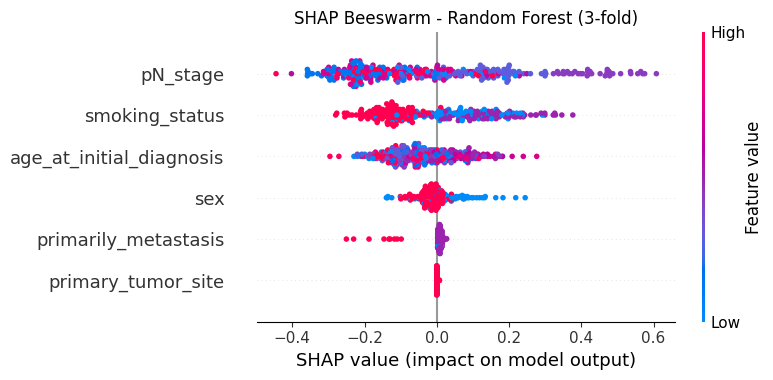


Mean absolute LIME importance across folds:
                 feature  mean_absolute_lime_weight
                pN_stage                   0.199722
          smoking_status                   0.182441
    primarily_metastasis                   0.127048
                     sex                   0.074439
      primary_tumor_site                   0.050123
age_at_initial_diagnosis                   0.011083


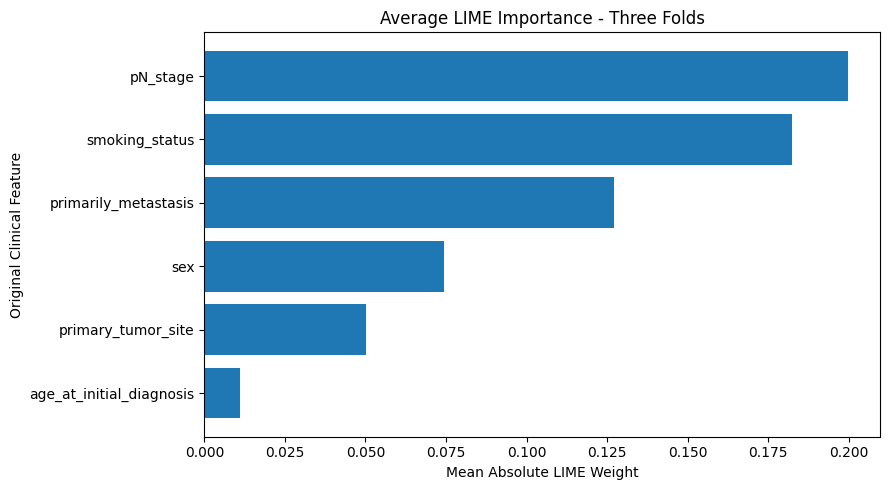


RANDOM FOREST42_HANCOCK — 3-FOLD SUMMARY
Model: Random Forest
Original predictors: 6
Mean encoded features: 18
Estimators: 100
Random state: 42
Validation: Stratified 3-fold cross-validation
Independent test set: None
SMOTE: No
Class weights: Automatic, calculated on each training fold
Preprocessing: Fitted on training fold only
Threshold: Validation balanced accuracy over np.linspace(0.10, 0.90, 161), selected separately per fold

Mean ± SD metrics:
           Metric     Mean       SD
         Accuracy 0.695850 0.033234
Balanced_Accuracy 0.688610 0.034852
        Precision 0.656318 0.083026
           Recall 0.638298 0.139520
               F1 0.636625 0.053278
          ROC_AUC 0.718439 0.044401
           PR_AUC 0.720483 0.041430
        Threshold 0.476667 0.214262

Saved results folder: /content/drive/MyDrive/RF_results
Analysis complete.


In [3]:
# ============================================================
# RF42_HANCOCK — RANDOM FOREST HPV CLASSIFICATION
# Preprocessing, 3-fold validation, and reporting aligned with LR42_HANCOCK.
# Random Forest model configuration retained.
# Six original predictors | Seed 42 | No SMOTE | No data leakage
# ============================================================
import os,json,random,warnings,joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from google.colab import drive
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix,classification_report,roc_curve,precision_recall_curve
warnings.filterwarnings("ignore",category=FutureWarning)
SEED=42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"]=str(SEED)
drive.mount("/content/drive")
# ------------------------------------------------------------
# 1. LOAD AND PREPARE DATA
# ------------------------------------------------------------
BASE="/content/drive/MyDrive"
OUT_DIR=os.path.join(BASE,"RF_results")
os.makedirs(OUT_DIR,exist_ok=True)
def load_json_table(path):
    """Load JSON tables stored as lists or common record wrappers."""
    with open(path,"r",encoding="utf-8") as f:
        obj=json.load(f)
    if isinstance(obj,list):
        return pd.DataFrame(obj)
    if isinstance(obj,dict):
        for key in ["data","records","patients","items"]:
            if key in obj and isinstance(obj[key],list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)
    raise ValueError(f"Cannot read table from {path}")
clinical=load_json_table(os.path.join(BASE,"clinical_data.json"))
pathology=load_json_table(os.path.join(BASE,"pathological_data.json"))
if "patient_id" not in clinical.columns or "patient_id" not in pathology.columns:
    raise KeyError("Both clinical and pathological files must contain patient_id.")
df=clinical.merge(pathology,on="patient_id",how="left",suffixes=("","_path"))
print("Merged data shape:",df.shape)
print("Duplicate patient rows before filtering:",int(df["patient_id"].duplicated().sum()))
target_candidates=["hpv_association_p16","hpv_association_p16_path"]
target_col=next((c for c in target_candidates if c in df.columns),None)
if target_col is None:
    raise KeyError(f"Target not found. Available columns: {df.columns.tolist()}")
def normalize_label(value):
    """Normalize the label variants accepted by the LR notebook."""
    if pd.isna(value):
        return np.nan
    label=str(value).strip().lower()
    if label in {"positive","pos","1","true","yes"}:
        return 1
    if label in {"negative","neg","0","false","no"}:
        return 0
    return np.nan
feature_candidates={"age_at_initial_diagnosis":["age_at_initial_diagnosis"],"sex":["sex"],"smoking_status":["smoking_status"],"primary_tumor_site":["primary_tumor_site"],"primarily_metastasis":["primarily_metastasis"],"pN_stage":["pN_stage","pN_stage_path","pathological_N_stage","pathologic_N_stage","pathological_n_stage","pN"]}
resolved={}
for feature,candidates in feature_candidates.items():
    match=next((c for c in candidates if c in df.columns),None)
    if match is None:
        raise KeyError(f"Missing predictor '{feature}'; checked {candidates}")
    resolved[feature]=match
model_df=pd.DataFrame(index=df.index)
model_df["patient_id"]=df["patient_id"]
for feature,source_col in resolved.items():
    model_df[feature]=df[source_col]
model_df["HPV_Label"]=df[target_col].map(normalize_label)
model_df=model_df.dropna(subset=["HPV_Label"]).copy()
model_df["HPV_Label"]=model_df["HPV_Label"].astype(int)
model_df=model_df.drop_duplicates(subset=["patient_id"],keep="first").copy()
features=list(feature_candidates.keys())
numeric_features=["age_at_initial_diagnosis"]
categorical_features=[c for c in features if c not in numeric_features]
missing_strings={"","nan","none","null","na","n/a"}
for col in categorical_features:
    def clean_category(value):
        if pd.isna(value):
            return np.nan
        value=str(value).strip()
        return np.nan if value.lower() in missing_strings else value
    model_df[col]=model_df[col].apply(clean_category)
model_df["age_at_initial_diagnosis"]=pd.to_numeric(model_df["age_at_initial_diagnosis"],errors="coerce")
print("\nTarget source:",target_col)
print("Predictors:",features)
print("Target distribution:")
print(model_df["HPV_Label"].value_counts().sort_index())
# ------------------------------------------------------------
# 2. STRATIFIED 3-FOLD CROSS-VALIDATION — NO TEST SET
# ------------------------------------------------------------
skf=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
print("\nRows:",len(model_df),"| 3-fold cross-validation | No independent test set")
fold_metrics=[]
oof_parts=[]
shap_importance=[]
shap_beeswarm_values=[]
shap_beeswarm_data=[]
category_codes={col:{value:i for i,value in enumerate(sorted(model_df[col].fillna("Missing").astype(str).unique()))} for col in categorical_features}
lime_importance=[]
rf_importance=[]
fold_thresholds=[]
models=[]
for fold,(train_idx,val_idx) in enumerate(skf.split(model_df[features],model_df["HPV_Label"]),1):
    print(f"\n{'='*18} FOLD {fold}/3 {'='*18}")
    train=model_df.iloc[train_idx].copy()
    val=model_df.iloc[val_idx].copy()
    print("Train:",len(train),"| Validation:",len(val))
    print("Class counts (train):",train["HPV_Label"].value_counts().sort_index().to_dict())
    print("Class counts (validation):",val["HPV_Label"].value_counts().sort_index().to_dict())
    # ------------------------------------------------------------
    # 3. PREPROCESSING — FIT ON TRAINING FOLD ONLY
    # ------------------------------------------------------------
    try:
        onehot=OneHotEncoder(handle_unknown="ignore",sparse_output=False)
    except TypeError:
        onehot=OneHotEncoder(handle_unknown="ignore",sparse=False)
    preprocessor=ColumnTransformer(transformers=[("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),numeric_features),("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",onehot)]),categorical_features)],remainder="drop",verbose_feature_names_out=False)
    X_train=preprocessor.fit_transform(train[features])
    X_val=preprocessor.transform(val[features])
    y_train=train["HPV_Label"].to_numpy()
    y_val=val["HPV_Label"].to_numpy()
    encoded_feature_names=preprocessor.get_feature_names_out().tolist()
    n_features=X_train.shape[1]
    # ------------------------------------------------------------
    # 4. AUTOMATIC CLASS WEIGHTS — TRAINING FOLD ONLY
    # ------------------------------------------------------------
    counts=np.bincount(y_train,minlength=2)
    if np.any(counts==0):
        raise ValueError("Both HPV classes must be present in the training fold.")
    class_weight_dict={i:float(len(y_train)/(2*counts[i])) for i in range(2)}
    print("Automatic class weights:",class_weight_dict)
    # ------------------------------------------------------------
    # 5. TRAIN RANDOM FOREST
    # ------------------------------------------------------------
    model=RandomForestClassifier(n_estimators=100,class_weight=class_weight_dict,random_state=SEED)
    model.fit(X_train,y_train)
    models.append({"model":model,"preprocessor":preprocessor,"fold":fold})
    # ------------------------------------------------------------
    # 6. SELECT THRESHOLD USING VALIDATION FOLD
    # ------------------------------------------------------------
    val_prob=model.predict_proba(X_val)[:,1]
    thresholds=np.linspace(0.10,0.90,161)
    threshold_scores=[balanced_accuracy_score(y_val,(val_prob>=threshold).astype(int)) for threshold in thresholds]
    best_score=max(threshold_scores)
    best_threshold=float(min((threshold for threshold,score in zip(thresholds,threshold_scores) if score==best_score),key=lambda threshold:abs(threshold-0.5)))
    fold_thresholds.append(best_threshold)
    val_pred=(val_prob>=best_threshold).astype(int)
    def calculate_metrics(y_true,probabilities,predictions,threshold):
        return {"Accuracy":accuracy_score(y_true,predictions),"Balanced_Accuracy":balanced_accuracy_score(y_true,predictions),"Precision":precision_score(y_true,predictions,zero_division=0),"Recall":recall_score(y_true,predictions,zero_division=0),"F1":f1_score(y_true,predictions,zero_division=0),"Threshold":float(threshold),"ROC_AUC":roc_auc_score(y_true,probabilities) if len(np.unique(y_true))==2 else np.nan,"PR_AUC":average_precision_score(y_true,probabilities) if len(np.unique(y_true))==2 else np.nan}
    metrics=calculate_metrics(y_val,val_prob,val_pred,best_threshold)
    fold_metrics.append({"Fold":fold,**metrics})
    oof_parts.append(pd.DataFrame({"patient_id":val["patient_id"].to_numpy(),"Fold":fold,"y_true":y_val,"probability_positive":val_prob,"prediction":val_pred}))
    print("Selected threshold:",f"{best_threshold:.3f}")
    print("Fold validation metrics:")
    print(pd.Series(metrics))
    # ------------------------------------------------------------
    # 7. SHAP — GROUP ONE-HOT VALUES INTO SIX ORIGINAL FEATURES
    # ------------------------------------------------------------
    explainer=shap.TreeExplainer(model)
    shap_values=explainer.shap_values(X_val)
    if isinstance(shap_values,list):
        shap_matrix=np.asarray(shap_values[1])
    else:
        shap_matrix=np.asarray(shap_values)
        if shap_matrix.ndim==3:
            shap_matrix=shap_matrix[:,:,1]
    grouped_shap=np.column_stack([shap_matrix[:,[i for i,name in enumerate(encoded_feature_names) if name==feature or name.startswith(feature+"_")]].sum(axis=1) for feature in features])
    shap_importance.append(np.abs(grouped_shap).mean(axis=0))
    shap_beeswarm_values.append(grouped_shap)
    shap_plot_data=val[features].copy()
    shap_plot_data["age_at_initial_diagnosis"]=pd.to_numeric(shap_plot_data["age_at_initial_diagnosis"],errors="coerce").fillna(train["age_at_initial_diagnosis"].median())
    for col in categorical_features:
        shap_plot_data[col]=shap_plot_data[col].fillna("Missing").astype(str).map(category_codes[col]).astype(float)
    shap_beeswarm_data.append(shap_plot_data[features].to_numpy(dtype=float))
    # ------------------------------------------------------------
    # 8. LIME — ORIGINAL SIX CLINICAL FEATURES
    # ------------------------------------------------------------
    train_lime=train[features].copy()
    val_lime=val[features].copy()
    category_maps={}
    for col in categorical_features:
        train_lime[col]=train_lime[col].fillna("Missing").astype(str)
        val_lime[col]=val_lime[col].fillna("Missing").astype(str)
        categories=sorted(train_lime[col].unique().tolist())
        category_maps[col]={value:i for i,value in enumerate(categories)}
        val_lime[col]=val_lime[col].map(category_maps[col]).fillna(0).astype(int)
        train_lime[col]=train_lime[col].map(category_maps[col]).astype(int)
    train_lime["age_at_initial_diagnosis"]=train_lime["age_at_initial_diagnosis"].fillna(train_lime["age_at_initial_diagnosis"].median())
    val_lime["age_at_initial_diagnosis"]=val_lime["age_at_initial_diagnosis"].fillna(train_lime["age_at_initial_diagnosis"].median())
    lime_train_array=train_lime.to_numpy(dtype=float)
    lime_val_array=val_lime.to_numpy(dtype=float)
    categorical_indices=[features.index(c) for c in categorical_features]
    categorical_names={features.index(col):{i:value for value,i in category_maps[col].items()} for col in categorical_features}
    def lime_predict(data):
        lime_df=pd.DataFrame(data,columns=features)
        lime_df["age_at_initial_diagnosis"]=pd.to_numeric(lime_df["age_at_initial_diagnosis"],errors="coerce")
        for col in categorical_features:
            reverse_map={i:value for value,i in category_maps[col].items()}
            lime_df[col]=[reverse_map.get(int(round(value)),next(iter(reverse_map.values()))) for value in lime_df[col]]
        return model.predict_proba(preprocessor.transform(lime_df[features]))
    lime_explainer=LimeTabularExplainer(lime_train_array,feature_names=features,class_names=["HPV Negative","HPV Positive"],categorical_features=categorical_indices,categorical_names=categorical_names,mode="classification",discretize_continuous=True,random_state=SEED)
    lime_fold_values=[]
    for row in lime_val_array:
        explanation=lime_explainer.explain_instance(row,lime_predict,num_features=len(features),labels=(1,))
        weights=dict(explanation.as_list(label=1))
        local=np.zeros(len(features))
        for i,feature in enumerate(features):
            local[i]=sum(abs(weight) for term,weight in weights.items() if term==feature or term.startswith(feature+" ") or term.startswith(feature+"="))
        lime_fold_values.append(local)
    lime_importance.append(np.mean(lime_fold_values,axis=0))
    # ------------------------------------------------------------
    # 9. RANDOM FOREST FEATURE IMPORTANCE — GROUPED TO SIX FEATURES
    # ------------------------------------------------------------
    rf_importance.append([model.feature_importances_[[i for i,name in enumerate(encoded_feature_names) if name==feature or name.startswith(feature+"_")]].sum() for feature in features])
# ------------------------------------------------------------
# 10. THREE-FOLD PERFORMANCE SUMMARY
# ------------------------------------------------------------
fold_results=pd.DataFrame(fold_metrics)
metric_columns=["Accuracy","Balanced_Accuracy","Precision","Recall","F1","ROC_AUC","PR_AUC","Threshold"]
summary=pd.DataFrame({"Metric":metric_columns,"Mean": [fold_results[c].mean() for c in metric_columns],"SD":[fold_results[c].std(ddof=1) for c in metric_columns]})
oof_predictions=pd.concat(oof_parts,ignore_index=True)
oof_metrics=calculate_metrics(oof_predictions["y_true"],oof_predictions["probability_positive"],oof_predictions["prediction"],float(np.mean(fold_thresholds)))
print("\nFold results:")
print(fold_results.to_string(index=False))
print("\n3-fold mean ± SD:")
print(summary.to_string(index=False))
print("\nPooled out-of-fold metrics:")
print(pd.Series(oof_metrics))
print("\nPooled out-of-fold confusion matrix:\n",confusion_matrix(oof_predictions["y_true"],oof_predictions["prediction"],labels=[0,1]))
print("\nPooled out-of-fold classification report:\n",classification_report(oof_predictions["y_true"],oof_predictions["prediction"],labels=[0,1],target_names=["HPV Negative","HPV Positive"],zero_division=0))
# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------
fold_results.to_csv(os.path.join(OUT_DIR,"3fold_metrics_by_fold.csv"),index=False)
summary.to_csv(os.path.join(OUT_DIR,"3fold_metrics_mean_sd.csv"),index=False)
oof_predictions.to_csv(os.path.join(OUT_DIR,"3fold_oof_predictions.csv"),index=False)
settings={"model":"RandomForestClassifier","seed":SEED,"features":features,"selected_source_columns":resolved,"target_column":target_col,"n_splits":3,"thresholds_per_fold":fold_thresholds,"class_weight":"Automatic, calculated on each training fold","smote":False,"split":"Stratified 3-fold cross-validation; no independent test set","preprocessing":"Median imputation and scaling for age; most-frequent imputation and one-hot encoding for categorical variables; fitted separately on each training fold"}
with open(os.path.join(OUT_DIR,"settings.json"),"w",encoding="utf-8") as f:
    json.dump(settings,f,indent=2)
joblib.dump(models,os.path.join(OUT_DIR,"RF42_Hancock_3fold_models.joblib"))
print("\nSaved 3-fold results to:",OUT_DIR)
# ------------------------------------------------------------
# 12. ROC / AUC CURVE — POOLED OUT-OF-FOLD PREDICTIONS
# ------------------------------------------------------------
fpr,tpr,_=roc_curve(oof_predictions["y_true"],oof_predictions["probability_positive"])
auc_curve=roc_auc_score(oof_predictions["y_true"],oof_predictions["probability_positive"])
plt.figure(figsize=(7,6))
plt.plot(fpr,tpr,linewidth=2,label=f"Random Forest 3-fold (AUC = {auc_curve:.4f})")
plt.plot([0,1],[0,1],linestyle="--",linewidth=1.5,label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest42 Hancock HPV (3-fold)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"roc_curve_3fold.png"),dpi=300,bbox_inches="tight")
plt.show()
# ------------------------------------------------------------
# 13. PRECISION-RECALL CURVE
# ------------------------------------------------------------
precision_values,recall_values,_=precision_recall_curve(oof_predictions["y_true"],oof_predictions["probability_positive"])
pr_auc_curve=average_precision_score(oof_predictions["y_true"],oof_predictions["probability_positive"])
plt.figure(figsize=(7,6))
plt.plot(recall_values,precision_values,linewidth=2,label=f"Random Forest 3-fold (PR AUC = {pr_auc_curve:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest42 Hancock (3-fold)")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"precision_recall_curve_3fold.png"),dpi=300,bbox_inches="tight")
plt.show()
# ------------------------------------------------------------
# 14. RANDOM FOREST FEATURE IMPORTANCE — SIX ORIGINAL FEATURES
# ------------------------------------------------------------
feature_importance=pd.DataFrame({"feature":features,"mean_importance":np.mean(rf_importance,axis=0)}).sort_values("mean_importance",ascending=False)
feature_importance.to_csv(os.path.join(OUT_DIR,"feature_importance_3fold.csv"),index=False)
print("\nMean Random Forest feature importance:")
print(feature_importance.to_string(index=False))
plt.figure(figsize=(9,5))
plt.barh(feature_importance.sort_values("mean_importance")["feature"],feature_importance.sort_values("mean_importance")["mean_importance"])
plt.xlabel("Mean Feature Importance")
plt.ylabel("Original Clinical Feature")
plt.title("Random Forest Feature Importance - 3-fold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"feature_importance_3fold.png"),dpi=300,bbox_inches="tight")
plt.show()
# ------------------------------------------------------------
# 15. SHAP — MEAN ABSOLUTE IMPORTANCE ACROSS THREE FOLDS
# ------------------------------------------------------------
shap_mean=np.mean(shap_importance,axis=0)
shap_df=pd.DataFrame({"feature":features,"mean_absolute_shap":shap_mean}).sort_values("mean_absolute_shap",ascending=False)
shap_df.to_csv(os.path.join(OUT_DIR,"shap_mean_importance_3fold.csv"),index=False)
print("\nMean absolute SHAP importance across folds:")
print(shap_df.to_string(index=False))
plt.figure(figsize=(9,5))
plt.barh(shap_df.sort_values("mean_absolute_shap")["feature"],shap_df.sort_values("mean_absolute_shap")["mean_absolute_shap"])
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Original Clinical Feature")
plt.title("Average SHAP Importance - Three Folds")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"shap_mean_importance_3fold.png"),dpi=300,bbox_inches="tight")
plt.show()
# ------------------------------------------------------------
# 15A. SHAP BEESWARM — POOLED OUT-OF-FOLD VALUES, SIX FEATURES
# ------------------------------------------------------------
all_shap_values=np.vstack(shap_beeswarm_values)
all_shap_data=np.vstack(shap_beeswarm_data)
plt.figure(figsize=(10,6))
shap.summary_plot(all_shap_values,all_shap_data,feature_names=features,plot_type="dot",max_display=6,show=False)
plt.title("SHAP Beeswarm - Random Forest (3-fold)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"shap_beeswarm_3fold.png"),dpi=300,bbox_inches="tight")
plt.show()
pd.DataFrame(all_shap_data,columns=features).to_csv(os.path.join(OUT_DIR,"shap_beeswarm_feature_values_3fold.csv"),index=False)
# ------------------------------------------------------------
# 16. LIME — MEAN ABSOLUTE IMPORTANCE ACROSS THREE FOLDS
# ------------------------------------------------------------
lime_mean=np.mean(lime_importance,axis=0)
lime_df=pd.DataFrame({"feature":features,"mean_absolute_lime_weight":lime_mean}).sort_values("mean_absolute_lime_weight",ascending=False)
lime_df.to_csv(os.path.join(OUT_DIR,"lime_mean_importance_3fold.csv"),index=False)
print("\nMean absolute LIME importance across folds:")
print(lime_df.to_string(index=False))
plt.figure(figsize=(9,5))
plt.barh(lime_df.sort_values("mean_absolute_lime_weight")["feature"],lime_df.sort_values("mean_absolute_lime_weight")["mean_absolute_lime_weight"])
plt.xlabel("Mean Absolute LIME Weight")
plt.ylabel("Original Clinical Feature")
plt.title("Average LIME Importance - Three Folds")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"lime_mean_importance_3fold.png"),dpi=300,bbox_inches="tight")
plt.show()
# ------------------------------------------------------------
# 17. MODEL SUMMARY
# ------------------------------------------------------------
print("\n====================================")
print("RANDOM FOREST42_HANCOCK — 3-FOLD SUMMARY")
print("====================================")
print("Model: Random Forest")
print("Original predictors:",len(features))
print("Mean encoded features:",int(np.mean([len(m["preprocessor"].get_feature_names_out()) for m in models])))
print("Estimators: 100")
print("Random state:",SEED)
print("Validation: Stratified 3-fold cross-validation")
print("Independent test set: None")
print("SMOTE: No")
print("Class weights: Automatic, calculated on each training fold")
print("Preprocessing: Fitted on training fold only")
print("Threshold: Validation balanced accuracy over np.linspace(0.10, 0.90, 161), selected separately per fold")
print("\nMean ± SD metrics:")
print(summary.to_string(index=False))
print("\nSaved results folder:",OUT_DIR)
print("Analysis complete.")

